# §5.4 — Comparação do modelo fluidodinâmico (Figuras 24–30, Tabelas 15–18, Apêndice A)

Linhas horizontais e verticais de 100 m, fluido CH₄/C7+ 70/30, grelha D × P_in × m da Tabela 16
(100 casos por orientação). Os valores de perda de carga da dissertação e dos cinco modelos do
HYSYS estão no Apêndice A (`dissertation/data/appendix_a_*.csv`), extraídos do PDF; as corridas do
cmfsim vêm do lote `batches/dp_comparison.json` (`runs/dp_comparison/`), modelo mecanicista
(método 3.2) e de não escorregamento (método 3.1). Não simula.

In [1]:
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parents[2] if "__file__" in globals() else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np

from dissertation.notebook_utils import RUNS, appendix_a, figure, load_runs, make_fluid, plt, save, table, tables

from cmfsim.thermo import FlashOptions, phase_state

INCH = 0.0254
grid = tables()["table16_dp_grid"]
cases = [(D, Pb, m) for D in grid["D_in"] for Pb in grid["P_in_bar"] for m in grid["m_kg_s"]]
LIT = {"horizontal": ("beggs_brill", "tulsa", "htfs", "gregory"), "vertical": ("beggs_brill", "tulsa", "htfs", "aziz")}
LIT_LABEL = dict(beggs_brill="Beggs & Brill", tulsa="TULSA", htfs="HTFS", gregory="Gregory et al.", aziz="Aziz et al.")


def dp_of(orientation, model):
    runs = load_runs(f"dp_comparison/dp_{orientation}_{model}_*.npz")
    out = np.full(100, np.nan)
    conv = np.zeros(100, bool)
    for name, r in runs.items():
        k = int(name.rsplit("_", 1)[1])
        out[k - 1] = (r.P[0] - r.P[-1]) / 1e5
        conv[k - 1] = bool(r.info.get("converged", True))
    return out, conv


data = {}
for orientation in ("horizontal", "vertical"):
    rows = appendix_a(orientation)
    ref = {c: np.array([float(r[f"dp_bar_{c}"]) for r in rows]) for c in ("dissertation",) + LIT[orientation]}
    mech, conv_m = dp_of(orientation, "mechanistic")
    nos, conv_n = dp_of(orientation, "noslip")
    data[orientation] = dict(ref=ref, mech=mech, nos=nos, conv=conv_m)
    print(
        f"{orientation}: corridas mecanicista {np.isfinite(mech).sum()} (convergidas {conv_m.sum()}), não escorregamento {np.isfinite(nos).sum()}"
    )

horizontal: corridas mecanicista 100 (convergidas 100), não escorregamento 100
vertical: corridas mecanicista 100 (convergidas 100), não escorregamento 100


## Tabela 18 — pressão na entrada × fração volumétrica de vapor (fluido da Tabela 17 a 40 °C)

In [2]:
cs, z = make_fluid("table17_dp_comparison")
t18 = tables()["table18_P_to_void_fraction_inlet"]
Pb = np.array([float(k) for k in t18])
st = phase_state(np.full(Pb.size, 313.15), Pb * 1e5, z, cs, FlashOptions(stability_test=True))
lam_G = (st.w_G / st.rho_V) / (st.w_G / st.rho_V + (1 - st.w_G) / st.rho_L)
table(
    [(f"{p:.0f}", f"{t18[str(int(p))]:.2f}", f"{l:.3f}") for p, l in zip(Pb, lam_G)],
    ["P (bar)", "R_G dissertação", "λ_G cmfsim (flash)"],
)

| P (bar) | R_G dissertação | λ_G cmfsim (flash) |


|---|---|---|
| 20 | 0.78 | 0.777 |
| 55 | 0.52 | 0.516 |
| 90 | 0.36 | 0.350 |
| 125 | 0.25 | 0.240 |
| 160 | 0.18 | 0.163 |


## Figuras 24–25 — modelos da literatura por caso (Apêndice A) e Figura 26 — histograma dos desvios máximos

figura: notebooks/figs/nb_5_4_fig24_25.png


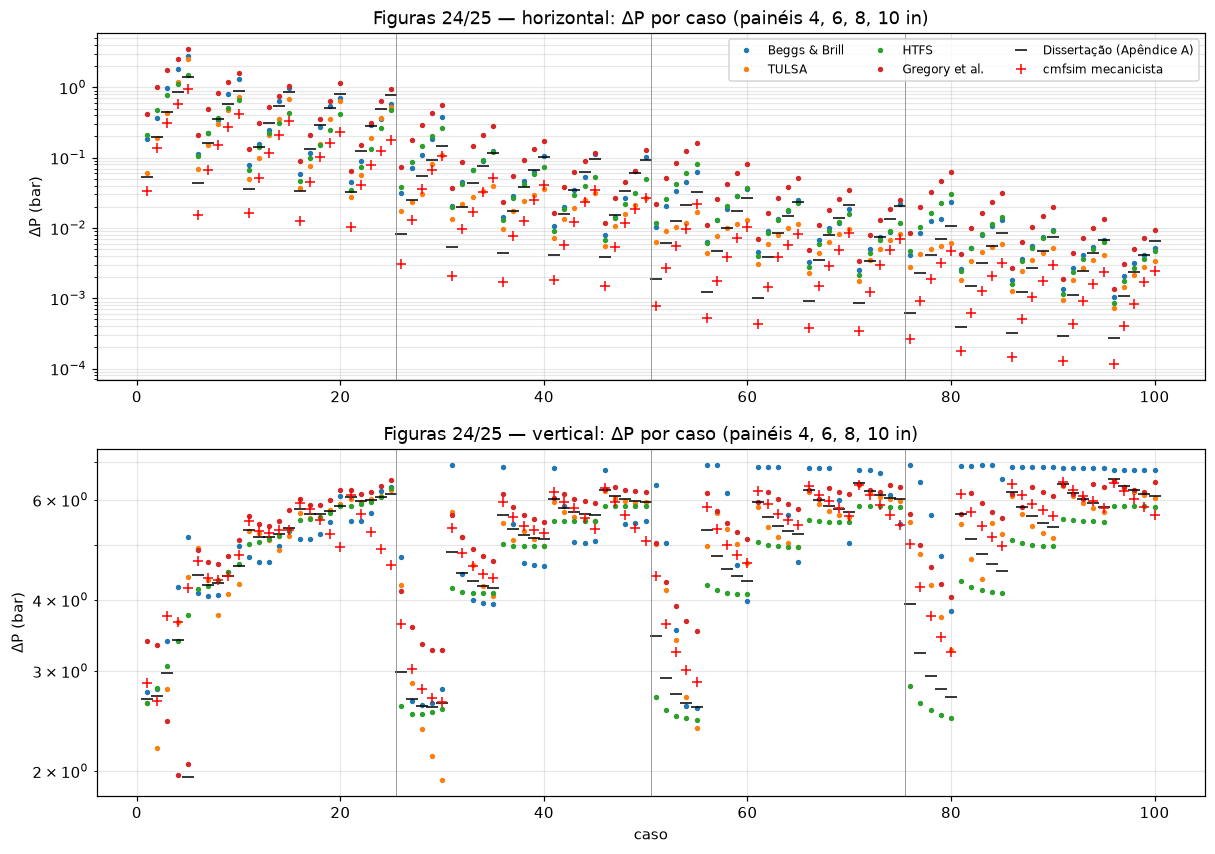

figura: notebooks/figs/nb_5_4_fig26.png


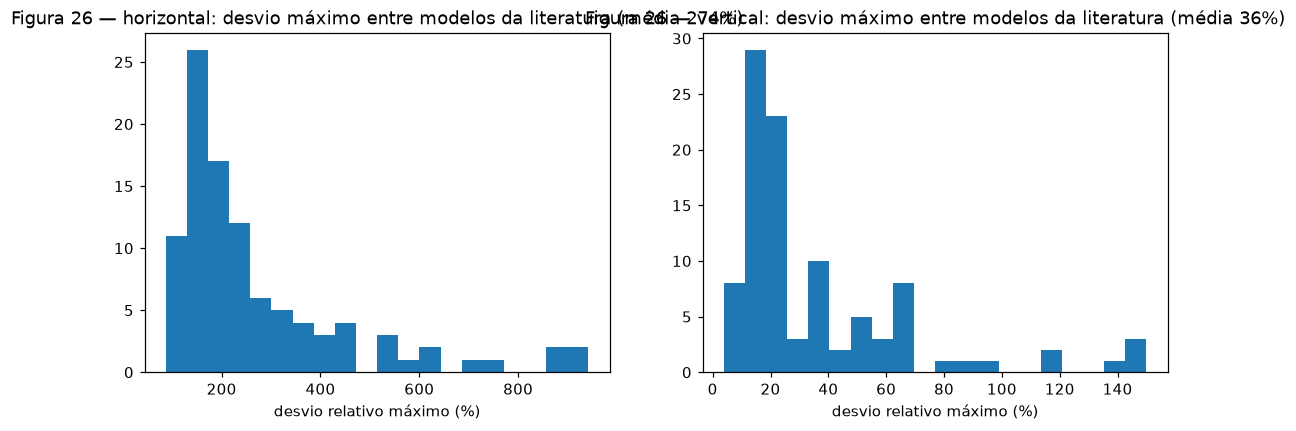

dissertação: médias de 375 % (horizontal) e 30 % (vertical); máximos 1200 % e 160 %


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9))
for ax, orientation in zip(axes, ("horizontal", "vertical")):
    ref = data[orientation]["ref"]
    for c in LIT[orientation]:
        ax.semilogy(np.arange(1, 101), ref[c], ".", ms=5, label=LIT_LABEL[c])
    ax.semilogy(np.arange(1, 101), ref["dissertation"], "k_", ms=8, label="Dissertação (Apêndice A)")
    ax.semilogy(np.arange(1, 101), data[orientation]["mech"], "r+", ms=7, label="cmfsim mecanicista")
    for k in (25.5, 50.5, 75.5):
        ax.axvline(k, color="gray", lw=0.5)
    ax.set_title(f"Figuras 24/25 — {orientation}: ΔP por caso (painéis 4, 6, 8, 10 in)")
    ax.set_ylabel("ΔP (bar)")
    ax.grid(alpha=0.3, which="both")
axes[0].legend(fontsize=8, ncol=3)
axes[1].set_xlabel("caso")
save(fig, "nb_5_4_fig24_25")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, orientation in zip(axes, ("horizontal", "vertical")):
    ref = data[orientation]["ref"]
    lit = np.stack([ref[c] for c in LIT[orientation]])
    dev = (lit.max(axis=0) - lit.min(axis=0)) / lit.min(axis=0)
    ax.hist(dev * 100, bins=20)
    ax.set_title(f"Figura 26 — {orientation}: desvio máximo entre modelos da literatura (média {dev.mean():.0%})")
    ax.set_xlabel("desvio relativo máximo (%)")
save(fig, "nb_5_4_fig26")
print("dissertação: médias de 375 % (horizontal) e 30 % (vertical); máximos 1200 % e 160 %")

## Figuras 27–28 — faixa da literatura e o modelo (dissertação e cmfsim)

figura: notebooks/figs/nb_5_4_fig27_28.png


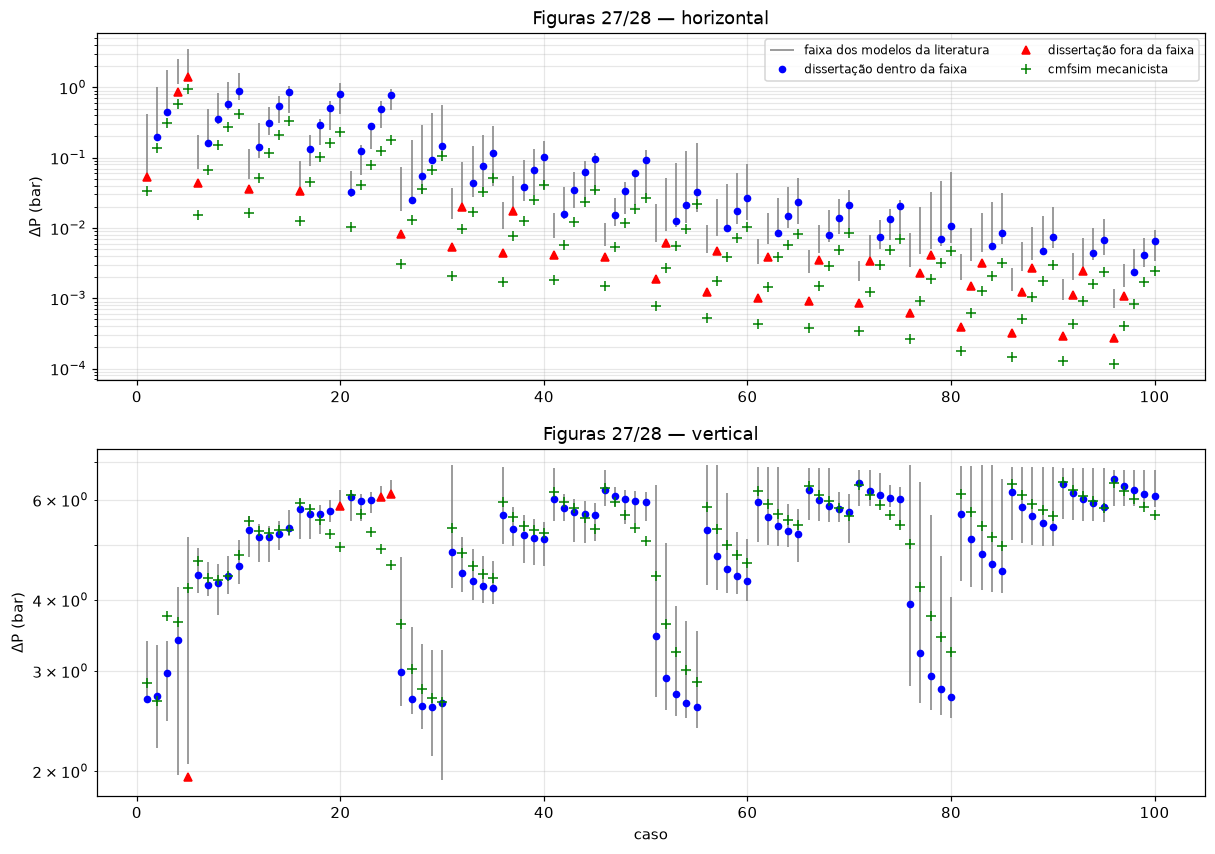

| orientação | dissertação dentro da faixa | cmfsim dentro da faixa |
|---|---|---|
| horizontal | 63% | 5% |
| vertical | 96% | 88% |
dissertação (texto): 63 % no horizontal; só 4 % abaixo da faixa no vertical


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(13, 9))
summary = []
for ax, orientation in zip(axes, ("horizontal", "vertical")):
    ref = data[orientation]["ref"]
    lit = np.stack([ref[c] for c in LIT[orientation]])
    lo, hi = lit.min(axis=0), lit.max(axis=0)
    k = np.arange(1, 101)
    ax.vlines(k, lo, hi, color="gray", lw=1, label="faixa dos modelos da literatura")
    d = ref["dissertation"]
    inside = (d >= lo) & (d <= hi)
    ax.semilogy(k[inside], d[inside], "bo", ms=4, label="dissertação dentro da faixa")
    ax.semilogy(k[~inside], d[~inside], "r^", ms=5, label="dissertação fora da faixa")
    m = data[orientation]["mech"]
    ax.semilogy(k, m, "g+", ms=7, label="cmfsim mecanicista")
    ins_m = (m >= lo) & (m <= hi)
    summary.append((orientation, f"{inside.mean():.0%}", f"{np.nanmean(ins_m):.0%}"))
    ax.set_title(f"Figuras 27/28 — {orientation}")
    ax.set_ylabel("ΔP (bar)")
    ax.grid(alpha=0.3, which="both")
axes[0].legend(fontsize=8, ncol=2)
axes[1].set_xlabel("caso")
save(fig, "nb_5_4_fig27_28")
table(summary, ["orientação", "dissertação dentro da faixa", "cmfsim dentro da faixa"])
print("dissertação (texto): 63 % no horizontal; só 4 % abaixo da faixa no vertical")

## Figura 29 — distribuição dos parâmetros nos 25 casos de cada diâmetro

figura: notebooks/figs/nb_5_4_fig29.png


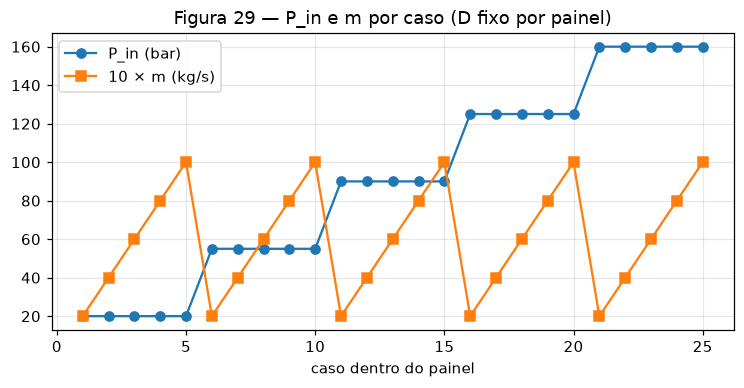

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.5))
k = np.arange(1, 26)
ax.plot(k, [c[1] for c in cases[:25]], "o-", label="P_in (bar)")
ax.plot(k, [10 * c[2] for c in cases[:25]], "s-", label="10 × m (kg/s)")
ax.set_xlabel("caso dentro do painel")
ax.legend()
ax.grid(alpha=0.3)
ax.set_title("Figura 29 — P_in e m por caso (D fixo por painel)")
save(fig, "nb_5_4_fig29")

## cmfsim contra a coluna «Dissertação»: desvios

| orientação | modelo | n | mediana | |máx| | < 10 % | < 25 % |
|---|---|---|---|---|---|---|
| horizontal | mecanicista (3.2) | 100 | -61.2% | 77% | 0% | 0% |
| horizontal | não escorregamento (3.1) | 100 | -53.9% | 70% | 0% | 16% |
| vertical | mecanicista (3.2) | 100 | +3.1% | 115% | 72% | 94% |
| vertical | não escorregamento (3.1) | 100 | -14.1% | 60% | 37% | 72% |


figura: notebooks/figs/nb_5_4_parity.png


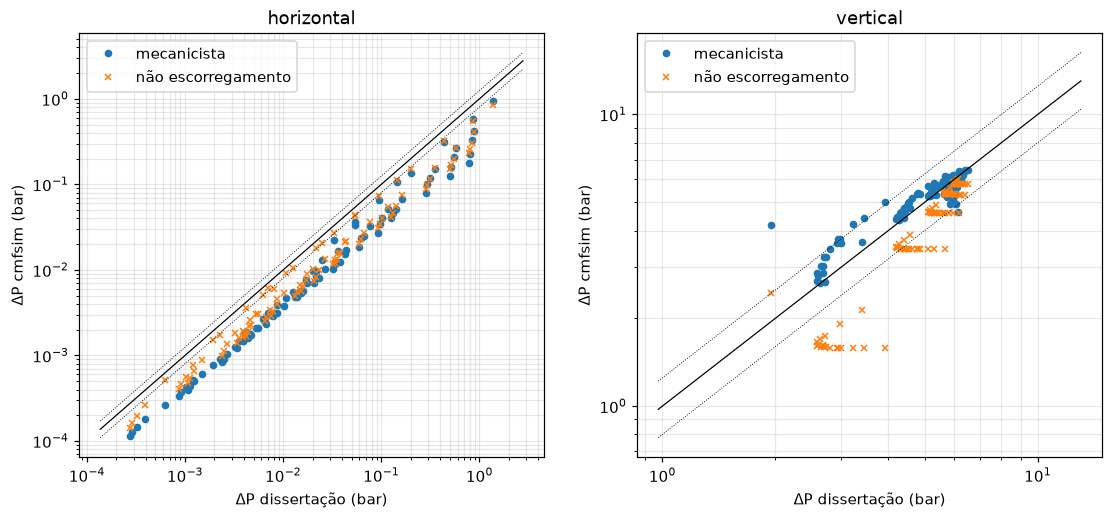

In [6]:
rows = []
for orientation in ("horizontal", "vertical"):
    ref = data[orientation]["ref"]["dissertation"]
    for model, key in (("mecanicista (3.2)", "mech"), ("não escorregamento (3.1)", "nos")):
        v = data[orientation][key]
        ok = np.isfinite(v)
        rel = (v[ok] - ref[ok]) / ref[ok]
        rows.append(
            (
                orientation,
                model,
                int(ok.sum()),
                f"{np.median(rel):+.1%}",
                f"{np.max(np.abs(rel)):.0%}",
                f"{np.mean(np.abs(rel) < 0.1):.0%}",
                f"{np.mean(np.abs(rel) < 0.25):.0%}",
            )
        )
table(rows, ["orientação", "modelo", "n", "mediana", "|máx|", "< 10 %", "< 25 %"])
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, orientation in zip(axes, ("horizontal", "vertical")):
    ref = data[orientation]["ref"]["dissertation"]
    ax.loglog(ref, data[orientation]["mech"], "o", ms=4, label="mecanicista")
    ax.loglog(ref, data[orientation]["nos"], "x", ms=4, label="não escorregamento")
    lo, hi = ref.min() * 0.5, ref.max() * 2
    ax.plot([lo, hi], [lo, hi], "k-", lw=0.8)
    ax.plot([lo, hi], [lo * 1.25, hi * 1.25], "k:", lw=0.6)
    ax.plot([lo, hi], [lo * 0.8, hi * 0.8], "k:", lw=0.6)
    ax.set_xlabel("ΔP dissertação (bar)")
    ax.set_ylabel("ΔP cmfsim (bar)")
    ax.set_title(orientation)
    ax.legend()
    ax.grid(alpha=0.3, which="both")
save(fig, "nb_5_4_parity")

## Figura 30 — mapa de padrão nas condições do caso 5 vertical (D 4 in, 20 bar, 10 kg/s)

figura: notebooks/figs/nb_5_4_fig30.png


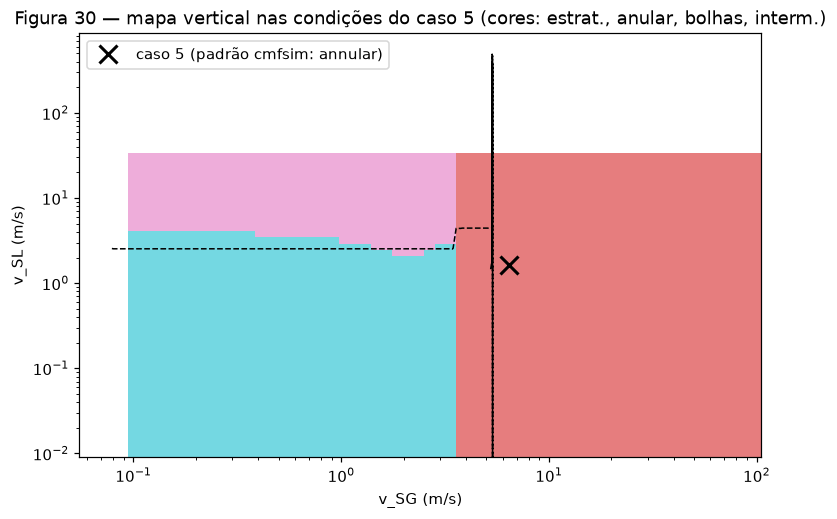

dissertação: o caso 5 fica na fronteira anular/intermitente e o algoritmo convergiu para anular


In [7]:
from cmfsim.backend import NUMPY
from cmfsim.closures import PATTERNS, ClosureOptions, FlowInputs, flow_closure

runs5 = load_runs("dp_comparison/dp_vertical_mechanistic_005.npz")
if runs5:
    r5 = next(iter(runs5.values()))
    j = len(r5.x) // 2
    VSG = np.logspace(-1, 2, 60)
    VSL = np.logspace(-2, 1.5, 50)
    G, L = np.meshgrid(VSG, VSL)
    inp = FlowInputs.build(
        bk=NUMPY,
        D=4 * INCH,
        eps=4.5e-5,
        theta=np.pi / 2,
        rho_L=r5["rho_L"][j],
        rho_G=r5["rho_V"][j],
        mu_L=r5["mu_L"][j],
        mu_G=r5["mu_V"][j],
        sigma=r5["sigma"][j],
        v_SL=L.ravel(),
        v_SG=G.ravel(),
    )
    _, w = flow_closure(inp, ClosureOptions(k_switch=None))
    code = np.argmax(w, axis=1).reshape(L.shape)
    fig, ax = plt.subplots(figsize=(8, 5))
    cmap = plt.get_cmap("tab10", 4)
    ax.pcolormesh(G, L, code, cmap=cmap, vmin=-0.5, vmax=3.5, shading="auto", alpha=0.6)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.plot(
        r5["v_SG"][j],
        r5["v_SL"][j],
        "kx",
        ms=12,
        mew=2,
        label=f"caso 5 (padrão cmfsim: {PATTERNS[int(np.argmax(r5['pattern_weights'][j]))]})",
    )
    f30 = figure(30)
    for nm, (x, y) in f30["series"].items():
        if x.size > 1:
            ax.plot(x, y, "k--", lw=1)
    ax.set_xlabel("v_SG (m/s)")
    ax.set_ylabel("v_SL (m/s)")
    ax.set_title("Figura 30 — mapa vertical nas condições do caso 5 (cores: estrat., anular, bolhas, interm.)")
    ax.legend()
    save(fig, "nb_5_4_fig30")
    print("dissertação: o caso 5 fica na fronteira anular/intermitente e o algoritmo convergiu para anular")